In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("matches.csv")
print(df.head())
print(df.info())

   id  season       city        date                        team1  \
0   1    2017  Hyderabad  2017-04-05          Sunrisers Hyderabad   
1   2    2017       Pune  2017-04-06               Mumbai Indians   
2   3    2017     Rajkot  2017-04-07                Gujarat Lions   
3   4    2017     Indore  2017-04-08       Rising Pune Supergiant   
4   5    2017  Bangalore  2017-04-08  Royal Challengers Bangalore   

                         team2                  toss_winner toss_decision  \
0  Royal Challengers Bangalore  Royal Challengers Bangalore         field   
1       Rising Pune Supergiant       Rising Pune Supergiant         field   
2        Kolkata Knight Riders        Kolkata Knight Riders         field   
3              Kings XI Punjab              Kings XI Punjab         field   
4             Delhi Daredevils  Royal Challengers Bangalore           bat   

   result  dl_applied                       winner  win_by_runs  \
0  normal           0          Sunrisers Hyderabad     

In [14]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
id                   0
season               0
city                 7
date                 0
team1                0
team2                0
toss_winner          0
toss_decision        0
result               0
dl_applied           0
winner               4
win_by_runs          0
win_by_wickets       0
player_of_match      4
venue                0
umpire1              2
umpire2              2
umpire3            637
dtype: int64


In [16]:
df['city'] = df['city'].fillna('Unknown')
df['winner'] = df['winner'].fillna('No Winner')
df['umpire3'] = df['umpire3'].fillna('Unknown')

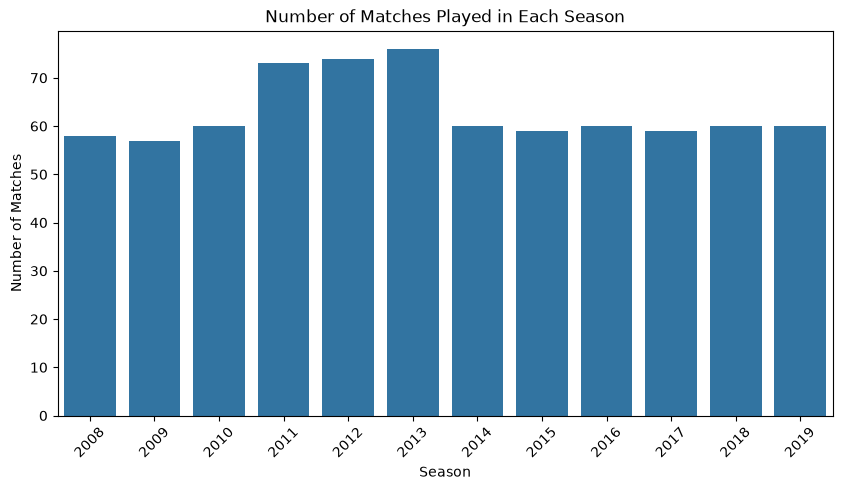

In [18]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='season')

plt.title("Number of Matches Played in Each Season")
plt.xlabel("Season")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45)

plt.show()

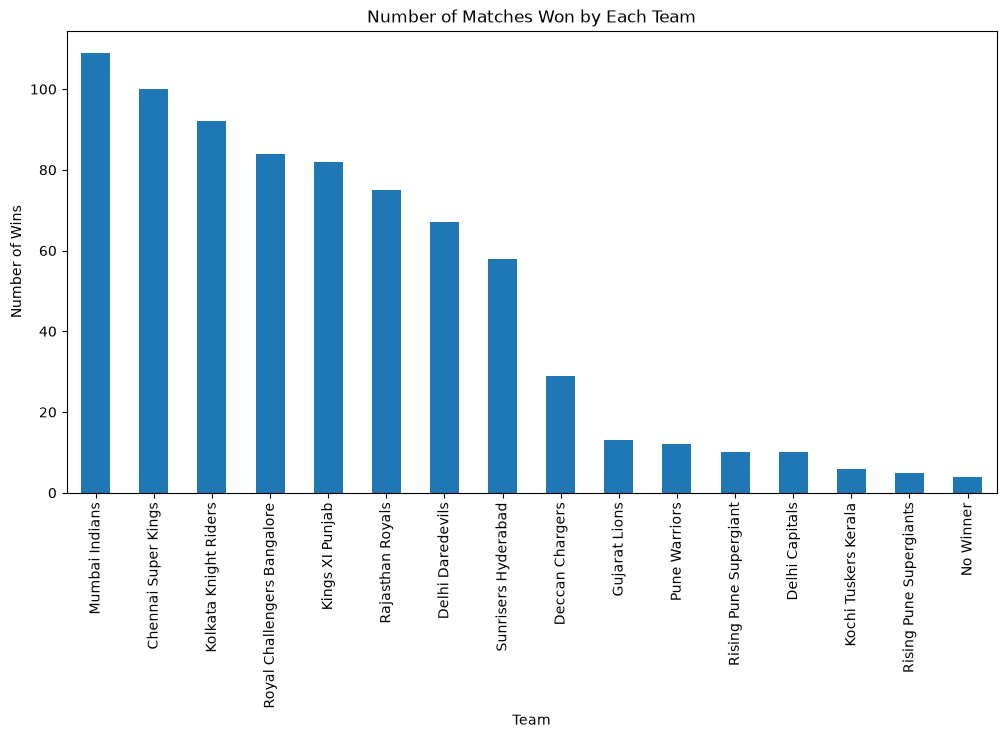

In [19]:
plt.figure(figsize=(12, 6))

winner_count = df['winner'].value_counts()

winner_count.plot(kind='bar')

plt.title("Number of Matches Won by Each Team")
plt.xlabel("Team")
plt.ylabel("Number of Wins")
plt.xticks(rotation=90)

plt.show()

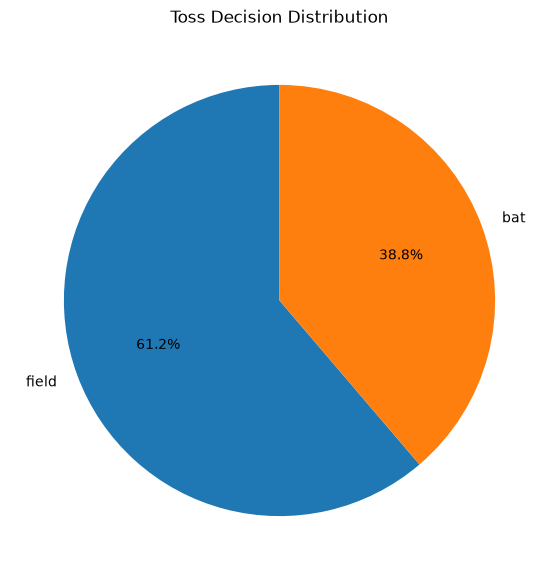

In [20]:
plt.figure(figsize=(7, 7))

toss_count = df['toss_decision'].value_counts()

plt.pie(
    toss_count,
    labels=toss_count.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Toss Decision Distribution")

plt.show()

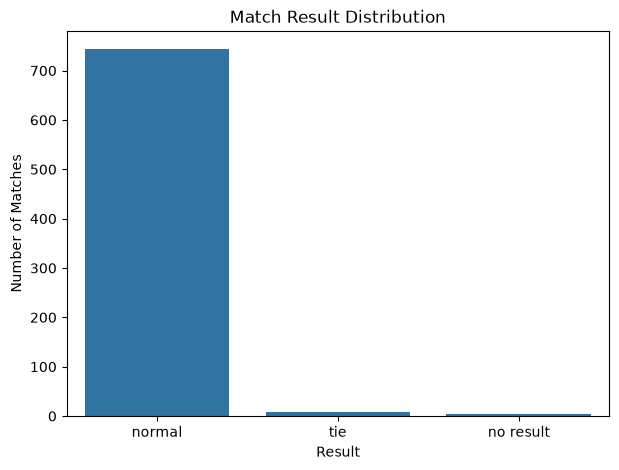

In [21]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='result')

plt.title("Match Result Distribution")
plt.xlabel("Result")
plt.ylabel("Number of Matches")

plt.show()

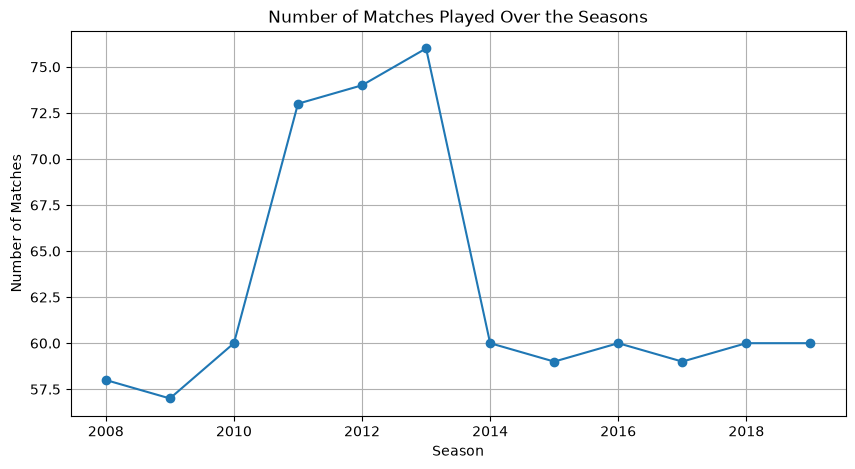

In [ ]:
season_count = df.groupby('season')['id'].count()

plt.figure(figsize=(10, 5))

plt.plot(
    season_count.index,
    season_count.values,
    marker='o'
)

plt.title("Number of Matches Played Over the Seasons")
plt.xlabel("Season")
plt.ylabel("Number of Matches")
plt.grid(True)

plt.show()

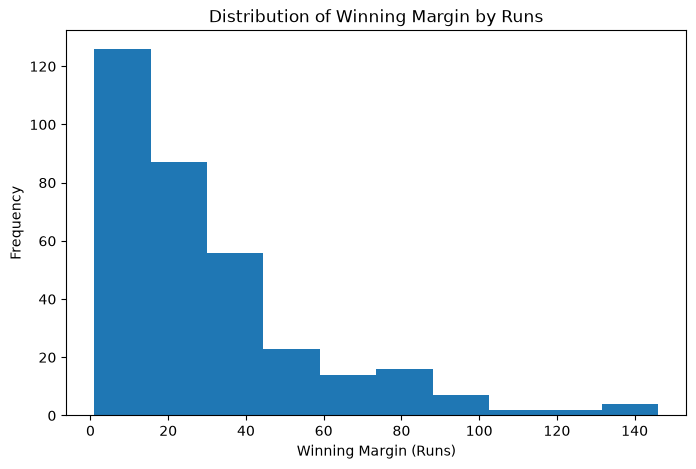

In [23]:
runs = df[df['win_by_runs'] > 0]['win_by_runs']

plt.figure(figsize=(8, 5))

plt.hist(runs, bins=10)

plt.title("Distribution of Winning Margin by Runs")
plt.xlabel("Winning Margin (Runs)")
plt.ylabel("Frequency")

plt.show()

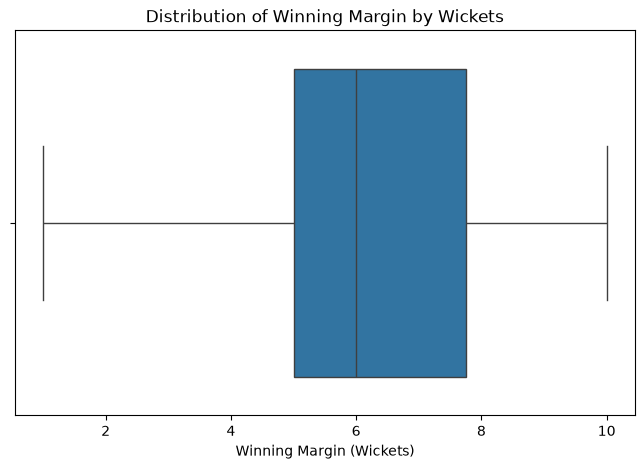

In [25]:
wickets = df[df['win_by_wickets'] > 0]['win_by_wickets']

plt.figure(figsize=(8, 5))

sns.boxplot(x=wickets)

plt.title("Distribution of Winning Margin by Wickets")
plt.xlabel("Winning Margin (Wickets)")

plt.show()

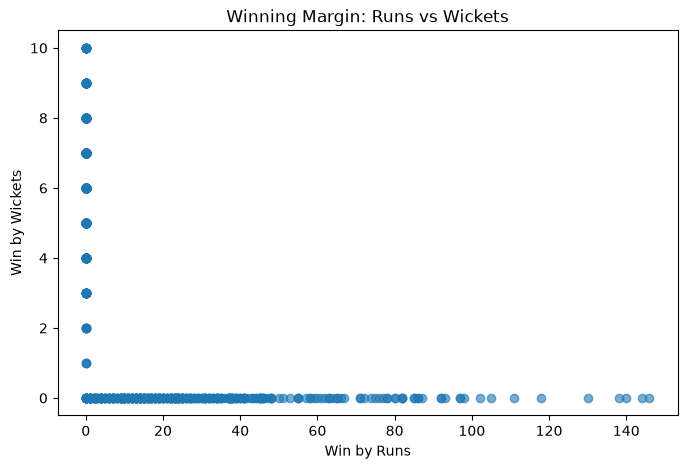

In [26]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['win_by_runs'],
    df['win_by_wickets'],
    alpha=0.6
)

plt.title("Winning Margin: Runs vs Wickets")
plt.xlabel("Win by Runs")
plt.ylabel("Win by Wickets")

plt.show()

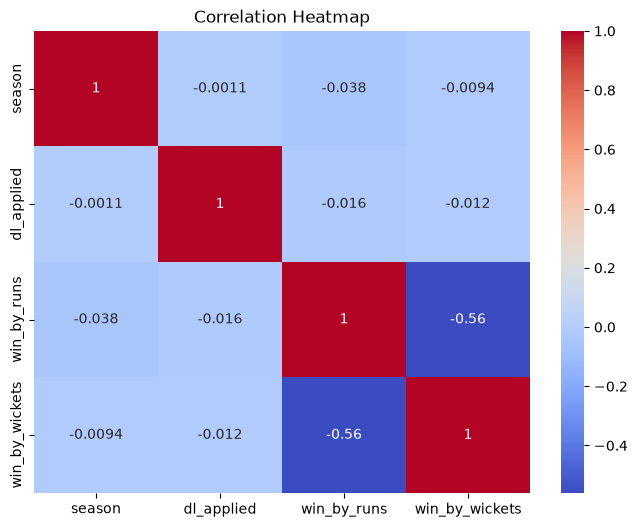

In [28]:
plt.figure(figsize=(8, 6))

numeric_data = df[
    ['season', 'dl_applied', 'win_by_runs', 'win_by_wickets']
]

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()